# Variant effects with gReLU on Epione models

[gReLU](https://github.com/Genentech/gReLU) (Genentech, MIT) builds a toolkit around one prediction API for sequence models:

* variant-effect prediction;
* in-silico mutagenesis (ISM);
* attributions (DeepLIFT-SHAP, saliency, integrated gradients);
* motif analyses.

`epione.models.grelu` makes Epione's own sequence models first-class gReLU models. `wrap()` turns a ChromBPNet or seq2PRINT model, or any one-hot PyTorch module, into a gReLU `LightningModel`, so every gReLU tool runs on it. `predict_variant_effects`, `ism` and `attributions` are exact pass-throughs that accept both Epione and native gReLU models, with a local FASTA as the genome.

This tutorial uses the bias-corrected ENCODE GM12878 ChromBPNet model; see `t_chrombpnet` for the model itself. It needs `pip install epione[grelu]`.

In [1]:
import logging
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfaidx
import torch

import epione as epi
from epione.models import chrombpnet as cbp
from epione.models import grelu as eg

torch.set_num_threads(8)
# gReLU predicts through a Lightning Trainer; keep its banners, tips and
# library warnings out of the output (import first: Lightning resets its
# log level when imported).
import grelu.lightning  # noqa: F401
warnings.filterwarnings("ignore")
for name in ("lightning", "lightning.pytorch", "pytorch_lightning", "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.ERROR)
fasta = str(epi.data.hg38.fasta)
model = cbp.load_pretrained("encode_gm12878", "nobias", fold=0)  # bias-corrected
lm = eg.wrap(model)          # head="counts": predicted log counts of the 1-kb window
print(type(lm).__module__ + "." + type(lm).__name__, lm.data_params)
eg.HEADS

grelu.lightning.LightningModel {'tasks': {'name': ['counts']}, 'train': {'seq_len': 2114, 'bin_size': 1}}


{'bpnet': ('counts', 'profile', 'profile_logits', 'expected_counts'),
 'chrombpnet': ('counts', 'profile', 'profile_logits', 'expected_counts'),
 'seq2print': ('coverage', 'footprints'),
 'module': ('output',)}

The wrapped model is a gReLU `LightningModel`, and its output is exactly the Epione model's log-count head: the bridge adds no arithmetic of its own.

In [2]:
x = torch.as_tensor(np.transpose(cbp.one_hot_encode(["ACGT" * 528 + "AC"]), (0, 2, 1)), dtype=torch.float32)
with torch.no_grad():
    print(lm(x).ravel().item(), model(x)[1].ravel().item())

10.200098037719727 10.200098037719727


## Breaking CTCF sites

CTCF binding is shared by GM12878 and blood lymphocytes. We take PBMC 3k peaks on held-out chromosomes (chr1, chr3, chr6) and find CTCF core matches (`CCA[CG][CT]AG[AG][GT]GG[CA]`, either strand) within 200 bp of the peak centre.

* **Motif variants:** mutate the conserved G of `AG[AG]GG` to its complement.
* **Controls:** a random substitution at least 50 bp from any match, in the same peaks.

Effects are predicted log fold changes of accessibility, alt minus ref, using `compare_func="subtract"` on the log-count head.

In [3]:
data = epi.datasets.pbmc3k_multiome_atac()
pk = pd.read_csv(data["peaks"], sep="\t", comment="#", header=None, usecols=[0, 1, 2],
                 names=["chr", "start", "end"])
pk = pk[pk["chr"].isin(["chr1", "chr3", "chr6"])].sort_values(["chr", "start"])
fa = pyfaidx.Fasta(fasta)
core = re.compile(r"(?=(CCA[CG][CT]AG[AG][GT]GG[CA]))")
core_rc = re.compile(r"(?=([TG]CC[AC][CT]CT[AG][GC]TGG))")
comp = dict(zip("ACGT", "TGCA"))
rng = np.random.RandomState(0)
motif, ctrl = [], []
for c, s, e in zip(pk["chr"], pk["start"], pk["end"]):
    mid = (s + e) // 2
    a = mid - 200
    seq = str(fa[c][a:mid + 200]).upper()
    hits = sorted([(m.start(), "+") for m in core.finditer(seq)] +
                  [(m.start(), "-") for m in core_rc.finditer(seq)])
    if not hits:
        continue
    off, strand = hits[0]
    k = off + (9 if strand == "+" else 3)
    motif.append((c, a + k + 1, seq[k], comp[seq[k]]))          # 1-based position
    far = [i for i in range(len(seq)) if seq[i] in "ACGT"
           and all(abs(i - (h + 6)) >= 50 for h, _ in hits)]
    i = int(rng.choice(far))
    ctrl.append((c, a + i + 1, seq[i], rng.choice([b for b in "ACGT" if b != seq[i]])))
    if len(motif) >= 300:
        break
cols = ["chrom", "pos", "ref", "alt"]
motif, ctrl = pd.DataFrame(motif, columns=cols), pd.DataFrame(ctrl, columns=cols)
motif.head()

,chrom,pos,ref,alt
0,chr1,181749,C,G
1,chr1,858086,A,T
2,chr1,869930,G,C
3,chr1,904780,G,C
4,chr1,921258,G,C


making dataset


Output()

making dataset


Output()

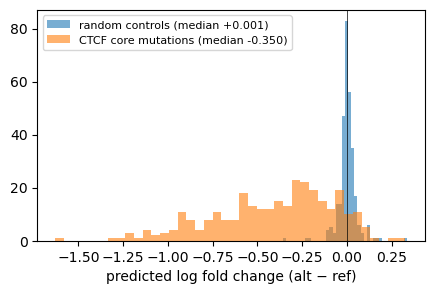

92% of CTCF core mutations decrease predicted accessibility; controls: 47%


In [4]:
eff_m = eg.predict_variant_effects(model, motif, fasta)   # AnnData: variants x tasks
eff_c = eg.predict_variant_effects(model, ctrl, fasta)
em, ec = eff_m.X.ravel(), eff_c.X.ravel()
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(ec, bins=40, alpha=0.6, label=f"random controls (median {np.median(ec):+.3f})")
ax.hist(em, bins=40, alpha=0.6, label=f"CTCF core mutations (median {np.median(em):+.3f})")
ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("predicted log fold change (alt − ref)")
ax.legend(fontsize=8)
plt.show()
print(f"{(em < 0).mean():.0%} of CTCF core mutations decrease predicted accessibility; "
      f"controls: {(ec < 0).mean():.0%}")

## In-silico mutagenesis around one site

`eg.ism` runs gReLU's `ISM_predict`, which mutates every base in a window and predicts every alternative. Here the window is ±30 bp around the CTCF core with the most negative effect.

Output()

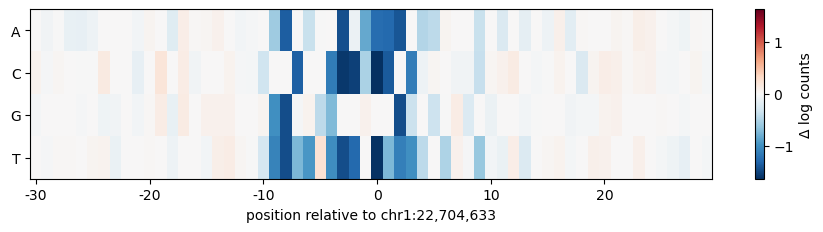

In [5]:
v = motif.iloc[int(np.argmin(em))]
L = model.input_len
start = v["pos"] - 1 - L // 2
seq = str(fa[v["chrom"]][start:start + L]).upper()
ism = eg.ism(model, seq, start_pos=L // 2 - 30, end_pos=L // 2 + 30)
fig, ax = plt.subplots(figsize=(11, 2.2))
im = ax.imshow(ism.values, aspect="auto", cmap="RdBu_r",
               vmin=-np.abs(ism.values).max(), vmax=np.abs(ism.values).max())
ax.set_yticks(range(4))
ax.set_yticklabels(ism.index)
ax.set_xticks(range(0, ism.shape[1], 10))
ax.set_xticklabels(range(-30, 30, 10))
ax.set_xlabel(f"position relative to {v['chrom']}:{v['pos']:,}")
plt.colorbar(im, ax=ax, label="Δ log counts")
plt.show()

## Attributions

`eg.attributions` runs gReLU's `get_attributions`. Here that is DeepLIFT-SHAP with 20 dinucleotide-shuffled references, via tangermeme. Multiplying by the one-hot sequence gives per-base contributions, and the CTCF motif stands out.

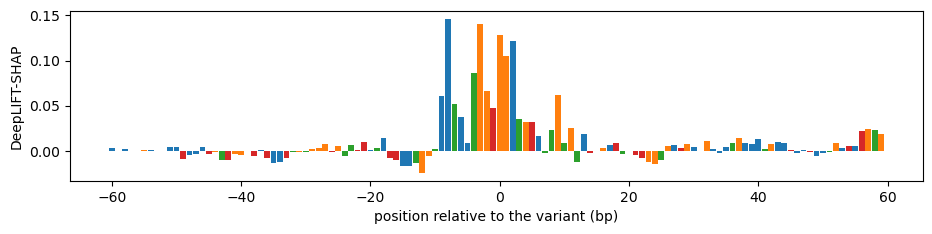

In [6]:
attr = eg.attributions(model, [seq], method="deepshap", n_shuffles=20, seed=0)[0]   # (4, L)
onehot = np.transpose(cbp.one_hot_encode([seq])[0])
contrib = (attr * onehot).sum(0)
w = slice(L // 2 - 60, L // 2 + 60)
bases = np.array(list(seq))[w]
colors = {"A": "tab:green", "C": "tab:blue", "G": "tab:orange", "T": "tab:red", "N": "grey"}
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.bar(np.arange(-60, 60), contrib[w], color=[colors[b] for b in bases], width=0.9)
ax.set_xlabel("position relative to the variant (bp)")
ax.set_ylabel("DeepLIFT-SHAP")
plt.show()

## Other models and training data

* **Other Epione models.** `wrap` also accepts seq2PRINT models, with `head="coverage"` or `"footprints"` and `cells=` for cell-state LoRA, and any `nn.Module` that maps `(N, 4, L)` one-hot input to a tensor. Native gReLU models, including the model zoo's Borzoi and Enformer, pass straight through every helper.
* **Training data.** `eg.pseudobulk_anndata(adata, groupby)` turns a cells × peaks matrix into the groups × peaks AnnData that gReLU's `AnnDataSeqDataset` trains on: tasks are groups, intervals are peaks.

## Validation

Registered in `tests/parity/grelu/MANIFEST.md` before running:

| Check | Result |
|---|---|
| V1, wrapped model = Epione model (bit-exact, `torch.equal`) | pass: all 10 model/head pairs (ChromBPNet BPNet and full model × 4 heads, seq2PRINT × 2) |
| V2, bridge = direct gReLU (`np.array_equal`) | pass: variant effects, ISM, saliency, DeepLIFT-SHAP |
| V3, CTCF sign test (ENCODE GM12878 nobias, 300 core mutations vs 300 controls, MACS3 summits) | pass: motifs median −0.361, 91.7% negative; controls median +0.004, 44% negative |
| V4, `pseudobulk_anndata` = groupby-sum | pass: identical |